# Do commodity price moves lead industry returns?

Course project for APM_5FI15_AE "ML for Trading" (ENSAE Paris, M2 SFA), Selim Lali, November 2026.

*Work in progress: for now the notebook only loads the data (Section 2).*

**Hypothesis.** Last month's moves in commodity prices (oil, gas, coal, metals, grains) predict next month's returns of the Ken French industry portfolios. The sign should depend on whether an industry produces the commodity (Oil, Coal, Mines, Gold, Agric) or uses it as an input (Trans, Chems, Autos, Util, Steel). The mechanism we have in mind is a slow diffusion of information from commodity markets to stock prices (Hong, Torous and Valkanov, 2007; Driesprong, Jacobsen and Maat, 2008).

**Plan of the notebook**, following the structure suggested in class:

1. Introduction
2. Data
3. Analytics and learning strategies
4. Empirical results: baseline and robustness
5. Conclusion

## Setup

The notebook only uses standard scientific Python packages (listed in `environment.yml`). Each dataset is downloaded once and cached as a parquet file in the `data/` folder next to the notebook. This folder is committed with the notebook, so the results can be reproduced even if a source is revised or a link breaks.

In [1]:
import io
import zipfile
from pathlib import Path

import numpy as np
import pandas as pd
import requests
import matplotlib.pyplot as plt

DATA_DIR = Path("data")  # downloads are cached here as parquet files
DATA_DIR.mkdir(exist_ok=True)

pd.set_option("display.width", 160)
plt.rcParams["figure.figsize"] = (9, 4.5)

## 1. Introduction

*To be written.*

## 2. Data

### 2.1 Industry returns: Ken French's 49 industry portfolios

Monthly value-weighted returns, in percent, of the 49 Fama-French industry portfolios, downloaded from Ken French's data library. We use the 49-industry classification rather than the 12 industries seen in class because commodity exposures are specific to narrow industries: Oil, Coal, Gold, Mines and Agric exist as separate portfolios only at this level of detail.

The csv file stacks several tables (monthly and annual returns, value- and equal-weighted, number of firms...). We only keep the first one, the monthly value-weighted returns. Missing values are coded `-99.99`: nine industries start after July 1926, some of them only in the 1960s.

In [2]:
KF_URL = "http://mba.tuck.dartmouth.edu/pages/faculty/ken.french/ftp/49_Industry_Portfolios_CSV.zip"


def load_industry_returns():
    """Monthly value-weighted returns (in %) of the 49 Fama-French industries, from Ken French's data library."""
    cache = DATA_DIR / "kf49_monthly_returns.parquet"
    if cache.exists():
        return pd.read_parquet(cache)

    response = requests.get(KF_URL, timeout=60)
    response.raise_for_status()
    with zipfile.ZipFile(io.BytesIO(response.content)) as archive:
        text = archive.read(archive.namelist()[0]).decode()

    # The tables are separated by blank lines; we keep the first one
    lines = text.splitlines()
    for i, line in enumerate(lines):
        if "Average Value Weighted Returns -- Monthly" in line:
            start = i + 1
            break
    end = start
    while lines[end].strip() != "":
        end += 1

    returns = pd.read_csv(io.StringIO("\n".join(lines[start:end])), index_col=0)
    returns.index = pd.to_datetime(returns.index.astype(str), format="%Y%m")
    returns.index.name = "month"
    returns.columns = returns.columns.str.strip()
    returns = returns.replace(-99.99, np.nan)  # Ken French's code for missing values
    returns.to_parquet(cache)
    return returns


industry_returns = load_industry_returns()
print(f"{industry_returns.shape[1]} industries, {len(industry_returns)} months, "
      f"from {industry_returns.index[0]:%Y-%m} to {industry_returns.index[-1]:%Y-%m}")
industry_returns.tail(3).round(2)

49 industries, 1203 months, from 1926-07 to 2026-09


,Agric,Food,Soda,Beer,Smoke,Toys,Fun,Books,Hshld,Clths,...,Boxes,Trans,Whlsl,Rtail,Meals,Banks,Insur,RlEst,Fin,Other
month,,,,,,,,,,,,,,,,,,,,,
2026-07-01,-6.16,4.69,5.89,1.30,2.28,1.62,0.05,6.47,-0.44,1.53,...,2.34,0.14,1.88,6.79,1.26,4.25,3.86,2.82,6.72,2.61
2026-08-01,5.71,2.45,0.15,0.33,-1.24,-2.58,6.47,-0.58,1.41,-8.73,...,-2.26,1.45,0.36,-3.77,-0.05,0.13,-1.06,-1.47,4.97,-1.85
2026-09-01,-8.36,-9.80,-3.84,-8.03,1.21,-5.75,-12.01,-4.89,-2.56,-7.20,...,-8.08,-9.26,-4.06,-4.22,-8.78,-6.99,-6.17,-13.05,-9.66,-2.02


In [3]:
# The industries that start after July 1926
has_gaps = industry_returns.columns[industry_returns.isna().any()]
pd.DataFrame({
    "first month": industry_returns[has_gaps].notna().idxmax().dt.strftime("%Y-%m"),
    "missing months": industry_returns[has_gaps].isna().sum(),
})

,first month,missing months
Soda,1963-07,444
Hlth,1969-07,516
Rubbr,1930-07,60
FabPr,1963-07,444
Guns,1963-07,444
Gold,1963-07,444
PerSv,1927-07,12
Softw,1965-07,468
Paper,1929-07,36


### 2.2 Commodity prices: the World Bank Pink Sheet

All commodity data come from a single source, the World Bank's Commodity Price Data, known as the "Pink Sheet": monthly average prices, in nominal US dollars, of about 70 commodities since January 1960. We chose it because it is the longest freely available monthly dataset that covers energy, metals and agricultural commodities together, in one documented file. We keep 24 commodities in six groups: energy, industrial metals, precious metals, grains, softs and livestock.

Two remarks on timing, since the whole project is about using *lagged* commodity moves:

- A value dated month $t$ is the average of the prices observed during month $t$. It is known at the end of month $t$, so it can be used to take positions for month $t+1$ without look-ahead bias.
- Monthly averages are smoother than end-of-month prices, which creates some autocorrelation in monthly changes (Working, 1960). We will check later that the results do not depend on this choice, for example with end-of-month futures prices.

In [4]:
PINK_SHEET_URL = ("https://thedocs.worldbank.org/en/doc/74e8be41ceb20fa0da750cda2f6b9e4e-0050012026"
                  "/related/CMO-Historical-Data-Monthly.xlsx")


def load_commodity_prices():
    """Monthly average commodity prices in nominal US dollars, from the World Bank Pink Sheet (since 1960)."""
    cache = DATA_DIR / "pink_sheet_monthly_prices.parquet"
    if cache.exists():
        return pd.read_parquet(cache)

    response = requests.get(PINK_SHEET_URL, timeout=60)
    response.raise_for_status()
    # In the "Monthly Prices" sheet, row 5 has the commodity names, row 6 the units, and the data start at row 7
    prices = pd.read_excel(io.BytesIO(response.content), sheet_name="Monthly Prices",
                           header=4, skiprows=[5], index_col=0)
    prices.index = pd.to_datetime(prices.index, format="%YM%m")  # dates are written like "1960M01"
    prices.index.name = "month"
    prices.columns = prices.columns.str.replace("**", "", regex=False).str.strip()  # "**" marks a footnote
    prices = prices.apply(pd.to_numeric, errors="coerce")
    prices.to_parquet(cache)
    return prices


pink_sheet = load_commodity_prices()
print(f"{pink_sheet.shape[1]} series, {len(pink_sheet)} months, "
      f"from {pink_sheet.index[0]:%Y-%m} to {pink_sheet.index[-1]:%Y-%m}")

71 series, 802 months, from 1960-01 to 2026-10


In [5]:
# The 24 commodities used in the project, by group (names as in the Pink Sheet)
COMMODITY_GROUPS = {
    "energy": ["Crude oil, average", "Crude oil, Brent", "Natural gas, US", "Coal, Australian"],
    "industrial metals": ["Copper", "Aluminum", "Nickel", "Zinc", "Lead", "Tin", "Iron ore, cfr spot"],
    "precious metals": ["Gold", "Silver", "Platinum"],
    "grains": ["Wheat, US HRW", "Maize", "Soybeans", "Rice, Thai 5%"],
    "softs": ["Sugar, world", "Cotton, A Index", "Coffee, Arabica", "Cocoa"],
    "livestock": ["Beef", "Chicken"],
}

commodity_group = {}
for group, names in COMMODITY_GROUPS.items():
    for name in names:
        commodity_group[name] = group
commodity_group = pd.Series(commodity_group, name="group")

commodity_prices = pink_sheet[commodity_group.index]

pd.DataFrame({
    "group": commodity_group,
    "first month": commodity_prices.notna().idxmax().dt.strftime("%Y-%m"),
    "months": commodity_prices.notna().sum(),
    "last price": commodity_prices.iloc[-1].round(2),
})

,group,first month,months,last price
"Crude oil, average",energy,1960-01,802,108.50
"Crude oil, Brent",energy,1960-01,802,125.00
"Natural gas, US",energy,1960-01,802,2.96
"Coal, Australian",energy,1970-01,682,152.30
Copper,industrial metals,1960-01,802,14508.00
Aluminum,industrial metals,1960-01,802,3061.00
Nickel,industrial metals,1960-01,802,15436.00
Zinc,industrial metals,1960-01,802,3818.00
Lead,industrial metals,1960-01,802,1860.00
Tin,industrial metals,1960-01,802,51696.00


### 2.3 A first look

Several series are flat in the 1960s: the price of oil was administered until 1973 and the gold price was fixed at 35 dollars an ounce until 1968. For these commodities the informative sample really starts in the early 1970s, which we will keep in mind when choosing the estimation period.

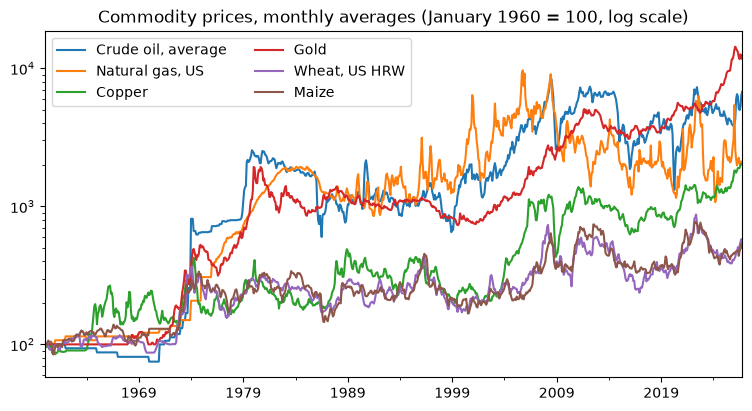

In [6]:
shown = ["Crude oil, average", "Natural gas, US", "Copper", "Gold", "Wheat, US HRW", "Maize"]
rebased = 100 * commodity_prices[shown] / commodity_prices[shown].iloc[0]

ax = rebased.plot(logy=True, title="Commodity prices, monthly averages (January 1960 = 100, log scale)")
ax.set_xlabel("")
ax.legend(loc="upper left", ncol=2)
plt.show()

*Next steps:* build the commodity features (1-, 3- and 12-month log price changes), define the common sample with the industry returns, and describe both panels (volatility, autocorrelation, contemporaneous industry-commodity correlations to classify industries as producers or users).